In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [2]:
import os, random, time, torch
import torch.nn as nn
import torchvision.models as models
import torchvision.transforms as transforms
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import accuracy_score, f1_score
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

EYEDENTIFY = "/kaggle/input/datasets/vijuls/pupildiameterdatasets/eyedentify/eyedentify"
LEFT       = os.path.join(EYEDENTIFY, "left_eyes")
OUTPUT     = "/kaggle/working"
device     = torch.device("cuda" if torch.cuda.is_available() else "cpu")

IMG_SIZE   = 64
BATCH_SIZE = 32
N_USERS    = 51

val_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225]),
])
train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225]),
])

subjects = sorted(os.listdir(LEFT))[:N_USERS]

def get_seqs(subject_path, label, sessions, seq_len, stride, max_seqs):
    seqs = []
    for sess in sessions:
        sess_path = os.path.join(subject_path, sess)
        if not os.path.isdir(sess_path): continue
        frames = sorted([os.path.join(sess_path, f)
                         for f in os.listdir(sess_path)
                         if f.lower().endswith(('.jpg','.png','.jpeg'))])
        for start in range(0, len(frames) - seq_len + 1, stride):
            seqs.append((frames[start:start+seq_len], label))
            if len(seqs) >= max_seqs: return seqs
    return seqs

def build_session_split(left_path, subjects, seq_len=10, stride=5,
                        max_per_subject=200, seed=42):
    random.seed(seed)
    train_seqs, val_seqs, test_seqs = [], [], []
    for label, subject in enumerate(subjects):
        s_path = os.path.join(left_path, subject)
        sessions = sorted([s for s in os.listdir(s_path)
                           if os.path.isdir(os.path.join(s_path, s))])
        n = len(sessions)
        n_train = max(1, int(n * 0.7))
        n_val   = max(1, int(n * 0.15))
        train_seqs.extend(get_seqs(s_path, label, sessions[:n_train],          seq_len, stride, max_per_subject))
        val_seqs.extend(get_seqs(  s_path, label, sessions[n_train:n_train+n_val], seq_len, stride, max(10, max_per_subject//4)))
        test_seqs.extend(get_seqs( s_path, label, sessions[n_train+n_val:],    seq_len, stride, max(10, max_per_subject//4)))
    return train_seqs, val_seqs, test_seqs

class EyeSeqDataset(Dataset):
    def __init__(self, seqs, transform):
        self.seqs, self.transform = seqs, transform
    def __len__(self): return len(self.seqs)
    def __getitem__(self, idx):
        paths, label = self.seqs[idx]
        return torch.stack([self.transform(Image.open(p).convert('RGB')) for p in paths]), label

print(f"✅ Device: {device} | GPU: {torch.cuda.get_device_name(0)}")
print(f"✅ Subjects: {N_USERS}")

✅ Device: cuda | GPU: Tesla T4
✅ Subjects: 51


In [3]:
# Cell 2 — Ablation Loop (fixed for 51 users)
SEQ_LENGTHS = [1, 5, 10, 20]
ablation_results = {}

class MobileNetExtractor(nn.Module):
    def __init__(self):
        super().__init__()
        mob = models.mobilenet_v2(weights='IMAGENET1K_V1')
        self.features = mob.features
        self.pool = nn.AdaptiveAvgPool2d((1,1))
        self.out_dim = 1280
        for p in self.parameters(): p.requires_grad = False
    def forward(self, x): return self.pool(self.features(x)).view(x.size(0), -1)

class EyeMotionModel(nn.Module):
    def __init__(self, n_users=51, hidden=256, layers=2, dropout=0.5):
        super().__init__()
        self.cnn = MobileNetExtractor()
        self.rnn = nn.GRU(1280, hidden, layers, batch_first=True,
                          dropout=dropout if layers>1 else 0)
        self.dropout    = nn.Dropout(dropout)
        self.classifier = nn.Linear(hidden, n_users)  # ← must match N_USERS
    def forward(self, x):
        B,T,C,H,W = x.shape
        feats = self.cnn(x.view(B*T,C,H,W)).view(B,T,-1)
        _, h = self.rnn(feats)
        return self.classifier(self.dropout(h[-1]))

print("=== Sequence Length Ablation (MobileNetV2 + GRU, 51 users) ===\n")
print(f"{'Seq Len':<10} {'Val Acc':>9} {'Test Acc':>9} {'F1':>9} {'Time':>8}")
print("-" * 50)

for seq_len in SEQ_LENGTHS:
    train_seqs, val_seqs, test_seqs = build_session_split(LEFT, subjects, seq_len=seq_len)
    train_loader = DataLoader(EyeSeqDataset(train_seqs, train_transform), batch_size=BATCH_SIZE, shuffle=True,  num_workers=2)
    val_loader   = DataLoader(EyeSeqDataset(val_seqs,   val_transform),   batch_size=BATCH_SIZE, shuffle=False, num_workers=2)
    test_loader  = DataLoader(EyeSeqDataset(test_seqs,  val_transform),   batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

    model     = EyeMotionModel(n_users=N_USERS).to(device)  # ← fixed
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(filter(lambda p: p.requires_grad, model.parameters()), lr=0.001, weight_decay=1e-4)

    best_val, best_state, start = 0.0, None, time.time()
    for epoch in range(1, 21):
        model.train()
        for imgs, lbls in train_loader:
            imgs, lbls = imgs.to(device), lbls.to(device)
            optimizer.zero_grad(); criterion(model(imgs), lbls).backward(); optimizer.step()
        model.eval()
        correct, total = 0, 0
        with torch.no_grad():
            for imgs, lbls in val_loader:
                imgs, lbls = imgs.to(device), lbls.to(device)
                correct += (model(imgs).argmax(1) == lbls).sum().item(); total += lbls.size(0)
        val_acc = correct / total
        if val_acc > best_val:
            best_val = val_acc
            best_state = {k: v.clone() for k, v in model.state_dict().items()}

    model.load_state_dict(best_state); model.eval()
    preds, labels = [], []
    with torch.no_grad():
        for imgs, lbls in test_loader:
            preds.extend(model(imgs.to(device)).argmax(1).cpu().numpy()); labels.extend(lbls.numpy())

    test_acc = accuracy_score(labels, preds)
    f1       = f1_score(labels, preds, average='macro')
    elapsed  = time.time() - start
    ablation_results[seq_len] = {'val_acc': best_val, 'test_acc': test_acc, 'f1': f1, 'time': elapsed}
    print(f"{seq_len:<10} {best_val:>8.2%} {test_acc:>8.2%} {f1:>8.2%} {elapsed:>6.0f}s")

print("\n✅ Ablation complete")

=== Sequence Length Ablation (MobileNetV2 + GRU, 51 users) ===

Seq Len      Val Acc  Test Acc        F1     Time
--------------------------------------------------
Downloading: "https://download.pytorch.org/models/mobilenet_v2-b0353104.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-b0353104.pth


100%|██████████| 13.6M/13.6M [00:00<00:00, 112MB/s] 


1            88.49%   87.61%   87.33%    850s
5            93.86%   92.90%   92.60%   3532s
10           93.64%   93.33%   93.01%   2808s
20           95.30%   93.01%   92.71%   5624s

✅ Ablation complete


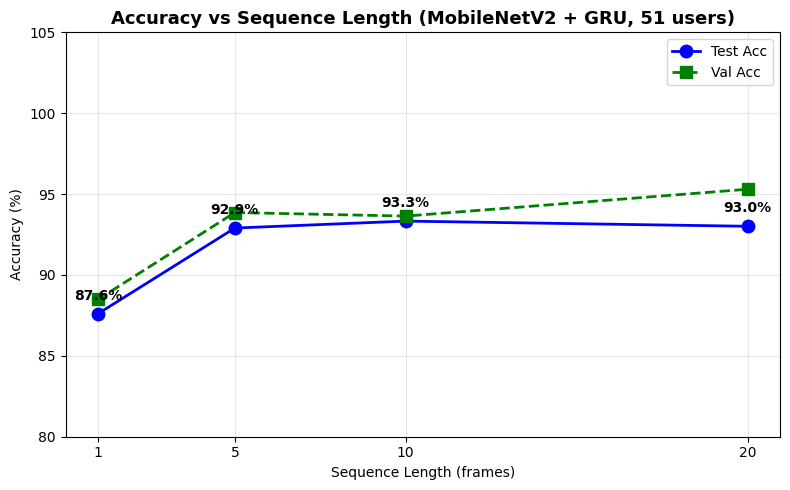

✅ Saved → ablation_seq_length.png


In [2]:
# Cell 3 — Plot ablation results (hardcoded)
import matplotlib.pyplot as plt

ablation_results = {
    1:  {'val_acc': 0.8849, 'test_acc': 0.8761, 'f1': 0.8733},
    5:  {'val_acc': 0.9386, 'test_acc': 0.9290, 'f1': 0.9260},
    10: {'val_acc': 0.9364, 'test_acc': 0.9333, 'f1': 0.9301},
    20: {'val_acc': 0.9530, 'test_acc': 0.9301, 'f1': 0.9271},
}

OUTPUT = "/kaggle/working"

seq_lens  = list(ablation_results.keys())
test_accs = [ablation_results[s]['test_acc']*100 for s in seq_lens]
val_accs  = [ablation_results[s]['val_acc']*100  for s in seq_lens]

plt.figure(figsize=(8, 5))
plt.plot(seq_lens, test_accs, 'b-o', markersize=9, linewidth=2, label='Test Acc')
plt.plot(seq_lens, val_accs,  'g--s', markersize=8, linewidth=2, label='Val Acc')
for x, y in zip(seq_lens, test_accs):
    plt.annotate(f"{y:.1f}%", (x, y), textcoords="offset points",
                 xytext=(0, 10), ha='center', fontsize=10, fontweight='bold')
plt.title("Accuracy vs Sequence Length (MobileNetV2 + GRU, 51 users)", fontsize=13, fontweight='bold')
plt.xlabel("Sequence Length (frames)")
plt.ylabel("Accuracy (%)")
plt.xticks(seq_lens)
plt.ylim(80, 105)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(f"{OUTPUT}/ablation_seq_length.png", dpi=100)
plt.show()
print("✅ Saved → ablation_seq_length.png")